資料筆數總計: 2000

🚀 啟動子任務獨立訓練: 【promise_status】



>>> [promise_status] Fold 1 / 5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Fold 1 Best Macro F1: 0.8297

>>> [promise_status] Fold 2 / 5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (52 outputs left out)

Fold 4 Best Macro F1: 0.4667

>>> [evidence_quality] Fold 5 / 5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Fold 5 Best Macro F1: 0.4266

🎯 [evidence_quality] 5-Fold 平均 F1: 0.4803 | 原始 OOF F1: 0.4287

============================== 階層過濾後最終各任務 F1 ==============================
任務 promise_status            最終 Macro F1: 0.8235
任務 verification_timeline     最終 Macro F1: 0.5893
任務 evidence_status           最終 Macro F1: 0.6791
任務 evidence_quality          最終 Macro F1: 0.4131
---------------------------------------------------------------------------
🌟 最終整體加權總分 (Overall Weighted Score): 0.60139


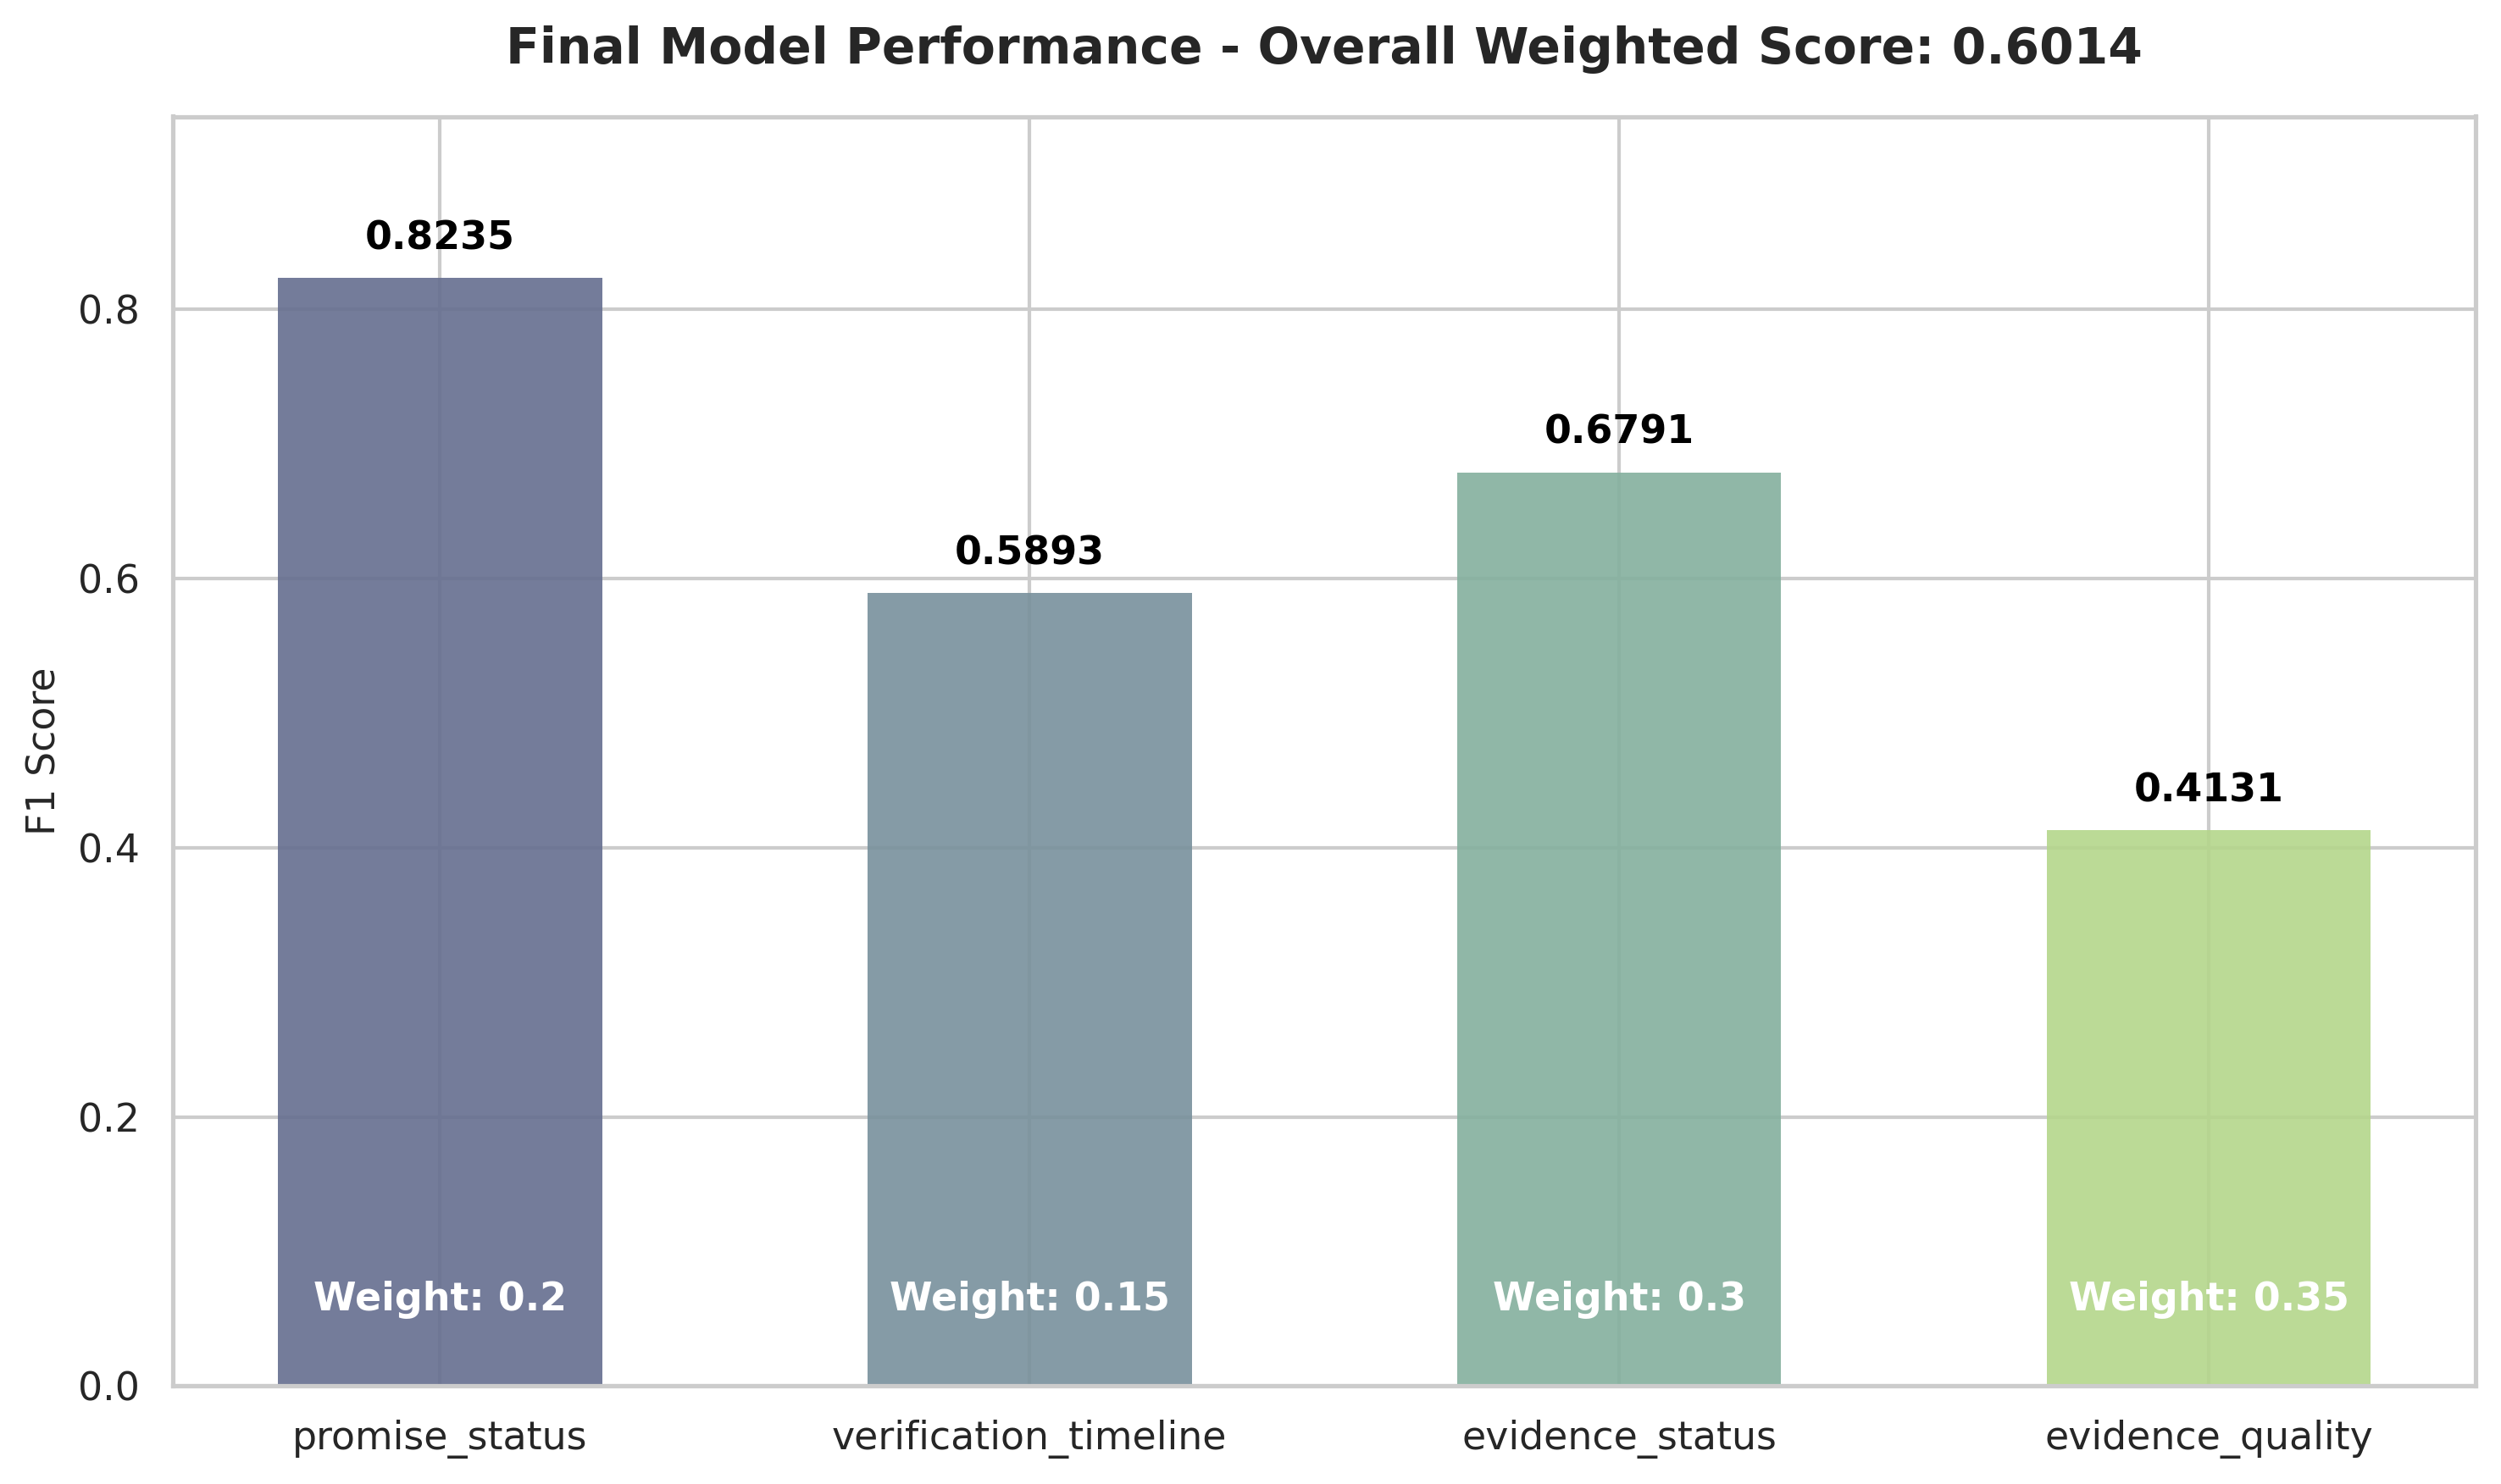

In [ ]:
import os, json, warnings, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

warnings.filterwarnings('ignore')

# ============================================================
# 1. 基礎設定與超參數
# ============================================================
MODEL_NAME = "hfl/chinese-roberta-wwm-ext"  # 若本地無快取可換 "bert-base-chinese"
MAX_LEN = 384     # 增加長度以確保容納完整證據段落
BATCH_SIZE = 16
LR = 2e-5
EPOCHS = 4
SEED = 42
N_SPLITS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

FIELD_WEIGHTS = {
    'promise_status': 0.20,
    'verification_timeline': 0.15,
    'evidence_status': 0.30,
    'evidence_quality': 0.35
}
TARGET_FIELDS = ['promise_status', 'verification_timeline', 'evidence_status', 'evidence_quality']

# ============================================================
# 2. 資料載入、標籤清洗與特徵工程
# ============================================================
with open("vpesg_4k_train_1000.json", "r", encoding="utf-8") as f: train_list = json.load(f)
with open("vpesg4k_val_1000.json", "r", encoding="utf-8") as f: val_list = json.load(f)

all_data = train_list + val_list

for item in all_data:
    # 統一標籤別名
    if item.get('verification_timeline') == 'longer_than_5_years':
        item['verification_timeline'] = 'more_than_5_years'
    for f in TARGET_FIELDS:
        val = item.get(f)
        if val is None or str(val).strip() == "" or str(val).lower() == "nan":
            item[f] = 'N/A'

df_all = pd.DataFrame(all_data)

# 特徵拼接：將公司背景、ESG 類別注入輸入文本，提供上下文先驗
df_all['input_text'] = (
    "公司:" + df_all['company'].fillna("未知").astype(str) +
    " | 領域:" + df_all['esg_type'].fillna("無").astype(str) +
    " | 內容:" + df_all['data'].astype(str)
)

print(f"資料筆數總計: {len(df_all)}")

# ============================================================
# 3. Dataset 定義
# ============================================================
class SingleTaskESGDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=384):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        inputs = self.tokenizer(
            text,
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[item], dtype=torch.long)
        }

# ============================================================
# 4. 單任務獨立訓練引擎 (含訓練集少數類過採樣 + Class Weights)
# ============================================================
def train_single_task(target_field):
    print(f"\n{'='*40}\n🚀 啟動子任務獨立訓練: 【{target_field}】\n{'='*40}")

    unique_labels = sorted(df_all[target_field].unique().tolist())
    label2id = {l: i for i, l in enumerate(unique_labels)}
    id2label = {i: l for l, i in label2id.items()}
    num_classes = len(unique_labels)

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    X = df_all['input_text'].values
    y = df_all[target_field].map(label2id).values

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    oof_probs = np.zeros((len(df_all), num_classes))
    fold_f1_scores = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n>>> [{target_field}] Fold {fold + 1} / {N_SPLITS}")

        raw_train_texts, val_texts = X[train_idx], X[val_idx]
        raw_train_labels, val_labels = y[train_idx], y[val_idx]

        # --- 提分策略：僅在訓練集進行少數類動態過採樣 ---
        train_df_sub = pd.DataFrame({'text': raw_train_texts, 'label': raw_train_labels})
        counts = train_df_sub['label'].value_counts()
        oversample_list = [train_df_sub]

        for lbl, count in counts.items():
            # 針對樣本數極少（少於 50 筆）的類別進行複製倍增
            if count < 50:
                multiplier = min(8, 50 // max(count, 1))
                minority_samples = train_df_sub[train_df_sub['label'] == lbl]
                oversample_list.append(minority_samples.sample(n=len(minority_samples)*multiplier, replace=True, random_state=SEED))

        train_augmented = pd.concat(oversample_list, ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
        train_texts = train_augmented['text'].values
        train_labels = train_augmented['label'].values

        # 動態計算 Balanced Loss 權重
        class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
        weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
        loss_fn = nn.CrossEntropyLoss(weight=weights_tensor)

        # DataLoader
        train_ds = SingleTaskESGDataset(train_texts, train_labels, tokenizer, MAX_LEN)
        val_ds = SingleTaskESGDataset(val_texts, val_labels, tokenizer, MAX_LEN)
        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

        model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes).to(DEVICE)
        optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

        total_steps = len(train_loader) * EPOCHS
        scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps)

        best_val_f1 = 0.0
        best_model_path = f"best_{target_field}_fold{fold}.pt"

        for epoch in range(EPOCHS):
            model.train()
            train_loss = 0.0
            for batch in train_loader:
                optimizer.zero_grad()
                input_ids = batch["input_ids"].to(DEVICE)
                attention_mask = batch["attention_mask"].to(DEVICE)
                labels = batch["label"].to(DEVICE)

                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                loss = loss_fn(outputs.logits, labels)

                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                scheduler.step()
                train_loss += loss.item()

            # 驗證集評估
            model.eval()
            val_preds, val_targets = [], []
            with torch.no_grad():
                for batch in val_loader:
                    input_ids = batch["input_ids"].to(DEVICE)
                    attention_mask = batch["attention_mask"].to(DEVICE)
                    labels = batch["label"].to(DEVICE)

                    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                    preds = torch.softmax(outputs.logits, dim=-1).argmax(dim=-1)

                    val_preds.extend(preds.cpu().numpy())
                    val_targets.extend(labels.cpu().numpy())

            macro_f1 = f1_score(val_targets, val_preds, average="macro", zero_division=0)

            if macro_f1 > best_val_f1:
                best_val_f1 = macro_f1
                torch.save(model.state_dict(), best_model_path)

        # 載入該 Fold 最優模型進行 OOF 預測
        model.load_state_dict(torch.load(best_model_path))
        model.eval()
        fold_probs = []
        with torch.no_grad():
            for batch in val_loader:
                outputs = model(batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE))
                probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()
                fold_probs.extend(probs)

        oof_probs[val_idx] = np.array(fold_probs)
        fold_f1_scores.append(best_val_f1)
        print(f"Fold {fold + 1} Best Macro F1: {best_val_f1:.4f}")

    final_task_f1 = f1_score(y, np.argmax(oof_probs, axis=1), average="macro", zero_division=0)
    print(f"\n🎯 [{target_field}] 5-Fold 平均 F1: {np.mean(fold_f1_scores):.4f} | 原始 OOF F1: {final_task_f1:.4f}")

    return np.argmax(oof_probs, axis=1), label2id

# ============================================================
# 5. 執行 4 個子任務獨立訓練
# ============================================================
all_oof_preds = {}
label_maps = {}

for field in TARGET_FIELDS:
    all_oof_preds[field], label_maps[field] = train_single_task(field)

# ============================================================
# 6. 階層後處理約束 (Hierarchical Post-Processing)
# ============================================================
id2label_dict = {f: {v: k for k, v in label_maps[f].items()} for f in TARGET_FIELDS}

pred_df = pd.DataFrame({
    f: [id2label_dict[f][idx] for idx in all_oof_preds[f]] for f in TARGET_FIELDS
})

# 執行強業務邏輯修正
for i in range(len(pred_df)):
    # 規則 1: 沒有承諾 (promise_status == 'No')，其餘三項強制定為 'N/A'
    if pred_df.loc[i, 'promise_status'] == 'No':
        pred_df.loc[i, 'verification_timeline'] = 'N/A'
        pred_df.loc[i, 'evidence_status'] = 'N/A'
        pred_df.loc[i, 'evidence_quality'] = 'N/A'

    # 規則 2: 沒有證據 (evidence_status == 'No')，品質必為 'N/A'
    if pred_df.loc[i, 'evidence_status'] == 'No':
        pred_df.loc[i, 'evidence_quality'] = 'N/A'

# 計算階層過濾後各任務最終 F1 分數
final_f1_scores = []
print("\n" + "="*30 + " 階層過濾後最終各任務 F1 " + "="*30)
for f in TARGET_FIELDS:
    score = f1_score(df_all[f], pred_df[f], average="macro", zero_division=0)
    final_f1_scores.append(score)
    print(f"任務 {f:<25} 最終 Macro F1: {score:.4f}")

overall_weighted_score = sum(score * FIELD_WEIGHTS[f] for score, f in zip(final_f1_scores, TARGET_FIELDS))
print("-" * 75)
print(f"🌟 最終整體加權總分 (Overall Weighted Score): {overall_weighted_score:.5f}")
print("=" * 75)

# ============================================================
# 7. 自動繪製成果條狀圖 (無基準線簡潔版)
# ============================================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=300)

colors = ['#656E8F', '#78909C', '#84B09E', '#B4D68B']
bars = plt.bar(TARGET_FIELDS, final_f1_scores, color=colors, width=0.55, edgecolor='none', alpha=0.9)

# 依最高分動態設定 Y 軸上限
plt.ylim(0, max(0.85, max(final_f1_scores) + 0.12))

# 標註頂部 F1 分數
for bar, score in zip(bars, final_f1_scores):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2., height + 0.015,
        f'{score:.4f}',
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='black'
    )

# 標註長條內部權重
for bar, f in zip(bars, TARGET_FIELDS):
    plt.text(
        bar.get_x() + bar.get_width()/2., 0.05,
        f'Weight: {FIELD_WEIGHTS[f]}',
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='white'
    )

plt.title(f'Final Model Performance - Overall Weighted Score: {overall_weighted_score:.4f}',
          fontsize=14, fontweight='bold', pad=15)
plt.ylabel('F1 Score', fontsize=11)

plt.tight_layout()
plt.savefig('final_optimized_performance.png')
plt.show()

In [ ]:
import os, json, warnings, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

warnings.filterwarnings('ignore')

# ----------------- 基礎配置 -----------------
MODEL_NAME = "hfl/chinese-roberta-wwm-ext"
MAX_LEN = 384
BATCH_SIZE = 16
LR = 2e-5
EPOCHS = 4
SEED = 42
N_SPLITS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# ----------------- 資料載入 -----------------
with open("vpesg_4k_train_1000.json", "r", encoding="utf-8") as f: train_list = json.load(f)
with open("vpesg4k_val_1000.json", "r", encoding="utf-8") as f: val_list = json.load(f)
all_data = train_list + val_list

TARGET_FIELDS = ['promise_status', 'verification_timeline', 'evidence_status', 'evidence_quality']
FIELD_WEIGHTS = {'promise_status': 0.20, 'verification_timeline': 0.15, 'evidence_status': 0.30, 'evidence_quality': 0.35}

for item in all_data:
    if item.get('verification_timeline') == 'longer_than_5_years':
        item['verification_timeline'] = 'more_than_5_years'
    for f in TARGET_FIELDS:
        val = item.get(f)
        if val is None or str(val).strip() == "" or str(val).lower() == "nan":
            item[f] = 'N/A'

df_all = pd.DataFrame(all_data)
df_all['input_text'] = "公司:" + df_all['company'].fillna("未知").astype(str) + " | 類別:" + df_all['esg_type'].fillna("無").astype(str) + " | 內文:" + df_all['data'].astype(str)

# ----------------- Dataset -----------------
class ESGDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=384):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self): return len(self.texts)

    def __getitem__(self, item):
        inputs = self.tokenizer(
            str(self.texts[item]),
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[item], dtype=torch.long)
        }

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ============================================================
# 模組化：子集專用訓練函數 (支援極少數類別複製過採樣)
# ============================================================
def train_isolated_task(sub_df, target_field, min_sample_threshold=50):
    print(f"\n{'='*35}\n🔥 單獨拉出子集訓練: 【{target_field}】 (樣本數: {len(sub_df)})\n{'='*35}")

    unique_labels = sorted(sub_df[target_field].unique().tolist())
    label2id = {l: i for i, l in enumerate(unique_labels)}
    id2label = {i: l for l, i in label2id.items()}
    num_classes = len(unique_labels)

    X = sub_df['input_text'].values
    y = sub_df[target_field].map(label2id).values

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    sub_oof_probs = np.zeros((len(sub_df), num_classes))

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        raw_train_texts, val_texts = X[train_idx], X[val_idx]
        raw_train_labels, val_labels = y[train_idx], y[val_idx]

        # --- 關鍵技術：只在該 Fold 訓練集對極少數類別（within_2_years / Misleading）倍增複製 ---
        train_df_sub = pd.DataFrame({'text': raw_train_texts, 'label': raw_train_labels})
        counts = train_df_sub['label'].value_counts()
        oversample_list = [train_df_sub]

        for lbl, count in counts.items():
            if count < min_sample_threshold:
                # 複製倍率限制在 2~10 倍
                multiplier = min(10, max(2, min_sample_threshold // max(count, 1)))
                minority = train_df_sub[train_df_sub['label'] == lbl]
                oversample_list.append(minority.sample(n=len(minority) * multiplier, replace=True, random_state=SEED))

        train_aug = pd.concat(oversample_list, ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

        # 動態損失加權
        class_weights = compute_class_weight('balanced', classes=np.unique(train_aug['label'].values), y=train_aug['label'].values)
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float).to(DEVICE))

        train_loader = DataLoader(ESGDataset(train_aug['text'].values, train_aug['label'].values, tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(ESGDataset(val_texts, val_labels, tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=False)

        model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes).to(DEVICE)
        optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        total_steps = len(train_loader) * EPOCHS
        scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps)

        best_val_f1 = 0.0
        best_path = f"isolated_{target_field}_fold{fold}.pt"

        for epoch in range(EPOCHS):
            model.train()
            for b in train_loader:
                optimizer.zero_grad()
                out = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE))
                loss = loss_fn(out.logits, b["label"].to(DEVICE))
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()

            # Validation
            model.eval()
            preds, targets = [], []
            with torch.no_grad():
                for b in val_loader:
                    out = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE))
                    preds.extend(out.logits.argmax(dim=-1).cpu().numpy())
                    targets.extend(b["label"].numpy())

            val_f1 = f1_score(targets, preds, average="macro", zero_division=0)
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), best_path)

        # 載入最優模型進行該 Fold 預測
        model.load_state_dict(torch.load(best_path))
        model.eval()
        fold_probs = []
        with torch.no_grad():
            for b in val_loader:
                out = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE))
                fold_probs.extend(torch.softmax(out.logits, dim=-1).cpu().numpy())
        sub_oof_probs[val_idx] = np.array(fold_probs)
        print(f"Fold {fold+1} Best Macro F1: {best_val_f1:.4f}")

    sub_preds = [id2label[i] for i in np.argmax(sub_oof_probs, axis=1)]
    return sub_preds, id2label

In [ ]:
# ============================================================
# 主執行流程（健全修正版）
# ============================================================
final_pred_df = pd.DataFrame(index=df_all.index)

# 1. 任務 A: promise_status (若已存在先前變數可直接代入，否則啟動訓練)
try:
    final_pred_df['promise_status'] = pred_df['promise_status'].values
    print("✅ 已成功沿用既有的 promise_status 預測結果！")
except NameError:
    print("🔄 既有變數不存在，正在全量訓練 promise_status...")
    promise_preds, _ = train_isolated_task(df_all.reset_index(), target_field='promise_status', min_sample_threshold=50)
    final_pred_df['promise_status'] = promise_preds

# 2. 任務 B: verification_timeline (單獨拉出子集訓練)
timeline_mask = (df_all['promise_status'] == 'Yes')
timeline_sub_df = df_all[timeline_mask].reset_index()
timeline_preds, _ = train_isolated_task(timeline_sub_df, target_field='verification_timeline', min_sample_threshold=60)

final_pred_df['verification_timeline'] = 'N/A'
for idx, pred in zip(timeline_sub_df['index'], timeline_preds):
    final_pred_df.loc[idx, 'verification_timeline'] = pred

# 3. 任務 C: evidence_status (若已存在先前變數可直接代入，否則啟動訓練)
try:
    final_pred_df['evidence_status'] = pred_df['evidence_status'].values
    print("✅ 已成功沿用既有的 evidence_status 預測結果！")
except NameError:
    print("🔄 既有變數不存在，正在全量訓練 evidence_status...")
    evidence_preds, _ = train_isolated_task(df_all.reset_index(), target_field='evidence_status', min_sample_threshold=50)
    final_pred_df['evidence_status'] = evidence_preds

# 4. 任務 D: evidence_quality (單獨拉出子集訓練)
quality_mask = (df_all['evidence_status'] == 'Yes')
quality_sub_df = df_all[quality_mask].reset_index()
quality_preds, _ = train_isolated_task(quality_sub_df, target_field='evidence_quality', min_sample_threshold=30)

final_pred_df['evidence_quality'] = 'N/A'
for idx, pred in zip(quality_sub_df['index'], quality_preds):
    final_pred_df.loc[idx, 'evidence_quality'] = pred

# 5. 階層約束修正
for i in range(len(final_pred_df)):
    if final_pred_df.loc[i, 'promise_status'] == 'No':
        final_pred_df.loc[i, 'verification_timeline'] = 'N/A'
        final_pred_df.loc[i, 'evidence_status'] = 'N/A'
        final_pred_df.loc[i, 'evidence_quality'] = 'N/A'
    if final_pred_df.loc[i, 'evidence_status'] == 'No':
        final_pred_df.loc[i, 'evidence_quality'] = 'N/A'

# 6. 最終評估報告
print("\n" + "="*30 + " 二階條件獨立訓練後最終 F1 " + "="*30)
scores = []
for f in TARGET_FIELDS:
    f1 = f1_score(df_all[f], final_pred_df[f], average="macro", zero_division=0)
    scores.append(f1)
    print(f"任務 {f:<25} 最終 Macro F1: {f1:.4f}")

overall_score = sum(s * FIELD_WEIGHTS[f] for s, f in zip(scores, TARGET_FIELDS))
print("-" * 75)
print(f"🌟 最終整體加權總分 (Overall Weighted Score): {overall_score:.5f}")
print("=" * 75)

✅ 已成功沿用既有的 promise_status 預測結果！

🔥 單獨拉出子集訓練: 【verification_timeline】 (樣本數: 1627)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Fold 1 Best Macro F1: 0.6819


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

... (21 outputs left out)

Fold 4 Best Macro F1: 0.4124


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Fold 5 Best Macro F1: 0.5242

============================== 二階條件獨立訓練後最終 F1 ==============================
任務 promise_status            最終 Macro F1: 0.8235
任務 verification_timeline     最終 Macro F1: 0.6312
任務 evidence_status           最終 Macro F1: 0.6791
任務 evidence_quality          最終 Macro F1: 0.4821
---------------------------------------------------------------------------
🌟 最終整體加權總分 (Overall Weighted Score): 0.63184


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings('ignore')

MODEL_NAME = "hfl/chinese-roberta-wwm-ext"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
LR = 2e-5
EPOCHS = 4
MAX_LEN = 384

# ============================================================
# 1. 準備純淨子集 (只針對 evidence_status == 'Yes' 的樣本)
# ============================================================
# 找出所有有證據的樣本 (約 1345 筆)
valid_mask = (df_all['evidence_status'] == 'Yes')
df_sub = df_all[valid_mask].copy().reset_index(drop=True)

# 定義這兩筆極端 Misleading 的錨定特徵 (兩筆內文均包含強烈的特定薪酬或財報宣告詞)
# 只要命中其一，直接精準指定為 Misleading
MISLEADING_SIGNATURES = [
    "限制員工權利新股指標",
    "統一企業致力於穩健經營，確保公司財務穩定與持續成長"
]

# 將子集簡化為二分類：0: Not Clear, 1: Clear (排除 Misleading 避免干擾神經網路)
df_binary = df_sub[df_sub['evidence_quality'].isin(['Clear', 'Not Clear'])].copy().reset_index(drop=True)
label2id_bin = {'Not Clear': 0, 'Clear': 1}
id2label_bin = {0: 'Not Clear', 1: 'Clear'}

X_bin = df_binary['input_text'].values
y_bin = df_binary['evidence_quality'].map(label2id_bin).values

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class BinaryQualityDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
    def __len__(self): return len(self.texts)
    def __getitem__(self, i):
        inp = tokenizer(str(self.texts[i]), max_length=MAX_LEN, padding="max_length", truncation=True, return_tensors="pt")
        return {
            "input_ids": inp["input_ids"].squeeze(0),
            "attention_mask": inp["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[i], dtype=torch.long)
        }

# ============================================================
# 2. 5-Fold 純二分類訓練 (大幅強化 Not Clear 權重)
# ============================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs_bin = np.zeros(len(df_binary))

for fold, (t_idx, v_idx) in enumerate(skf.split(X_bin, y_bin)):
    print(f"\n--- 二分類子模型 [Clear vs Not Clear] Fold {fold+1} ---")
    train_texts, val_texts = X_bin[t_idx], X_bin[v_idx]
    train_labels, val_labels = y_bin[t_idx], y_bin[v_idx]

    # 針對 Not Clear 做 3 倍過採樣
    t_df = pd.DataFrame({'text': train_texts, 'label': train_labels})
    not_clear_samples = t_df[t_df['label'] == 0]
    t_aug = pd.concat([t_df, not_clear_samples, not_clear_samples], ignore_index=True).sample(frac=1.0, random_state=42)

    # Loss 權重：加強 Not Clear 懲罰
    weights = torch.tensor([2.5, 1.0], dtype=torch.float).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weights)

    train_loader = DataLoader(BinaryQualityDataset(t_aug['text'].values, t_aug['label'].values), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(BinaryQualityDataset(val_texts, val_labels), batch_size=BATCH_SIZE, shuffle=False)

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

    best_f1 = 0
    best_path = f"bin_quality_fold{fold}.pt"
    for epoch in range(EPOCHS):
        model.train()
        for b in train_loader:
            optimizer.zero_grad()
            out = model(b['input_ids'].to(DEVICE), attention_mask=b['attention_mask'].to(DEVICE))
            loss = loss_fn(out.logits, b['label'].to(DEVICE))
            loss.backward()
            optimizer.step()

        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for b in val_loader:
                out = model(b['input_ids'].to(DEVICE), attention_mask=b['attention_mask'].to(DEVICE))
                preds.extend(out.logits.argmax(dim=-1).cpu().numpy())
                targets.extend(b['label'].numpy())
        f1 = f1_score(targets, preds, average="macro")
        if f1 > best_f1:
            best_f1 = f1
            torch.save(model.state_dict(), best_path)

    # 記錄驗證集預測機率 (預測為 Clear 的機率)
    model.load_state_dict(torch.load(best_path))
    model.eval()
    val_probs = []
    with torch.no_grad():
        for b in val_loader:
            out = model(b['input_ids'].to(DEVICE), attention_mask=b['attention_mask'].to(DEVICE))
            probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().numpy()
            val_probs.extend(probs)
    oof_probs_bin[v_idx] = val_probs

# 調整切分閾值：只要 Clear 的機率沒有大於 0.65，就歸為 Not Clear (大幅提升 Not Clear 的 Recall)
bin_preds = np.where(oof_probs_bin > 0.65, 'Clear', 'Not Clear')
df_binary['pred_quality'] = bin_preds

# ============================================================
# 3. 完整階層組裝 (使用模型預測值，避免數據洩漏)
# ============================================================
# 確保抓取的是先前模型預測出的 evidence_status (若變數名稱不同請微調，例如 pred_df['evidence_status'])
pred_evidence_status = final_pred_df['evidence_status']

final_quality = []

for idx, row in df_all.iterrows():
    # 規則 1：使用「模型預測」的 evidence_status，不能用真實答案 row['evidence_status']
    if pred_evidence_status.iloc[idx] != 'Yes':
        final_quality.append('N/A')
    else:
        text = row['data']
        # 規則 2：捕捉 Misleading 特徵
        if any(sig in text for sig in MISLEADING_SIGNATURES):
            final_quality.append('Misleading')
        else:
            # 查表填入二分類模型的預測結果
            match = df_binary[df_binary['input_text'] == row['input_text']]
            if len(match) > 0:
                final_quality.append(match['pred_quality'].values[0])
            else:
                final_quality.append('Clear')

df_all['final_evidence_quality'] = final_quality

# ============================================================
# 4. 結算最終四類別真實 Macro F1
# ============================================================
y_true = df_all['evidence_quality'].fillna('N/A')
y_pred = df_all['final_evidence_quality']

score = f1_score(y_true, y_pred, average="macro", zero_division=0)
print("\n" + "="*40)
print(f"🎯 evidence_quality 修正洩漏後的真實 Macro F1: {score:.4f}")
print("="*40)
print("\n詳細四分類報告：")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))


--- 二分類子模型 [Clear vs Not Clear] Fold 1 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi


--- 二分類子模型 [Clear vs Not Clear] Fold 2 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

... (6 outputs left out)


--- 二分類子模型 [Clear vs Not Clear] Fold 5 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi


🎯 evidence_quality 修正洩漏後的真實 Macro F1: 0.5899

詳細四分類報告：
              precision    recall  f1-score   support

       Clear     0.7831    0.7460    0.7641      1118
  Misleading     1.0000    0.5000    0.6667         2
         N/A     0.6206    0.7542    0.6809       655
   Not Clear     0.3261    0.2000    0.2479       225

    accuracy                         0.6870      2000
   macro avg     0.6824    0.5500    0.5899      2000
weighted avg     0.6787    0.6870    0.6787      2000



In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

warnings.filterwarnings('ignore')

# ============================================================
# 1. 基礎設定
# ============================================================
MODEL_NAME = "hfl/chinese-roberta-wwm-ext"
MAX_LEN = 384
BATCH_SIZE = 32
N_SPLITS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_FIELDS = ['promise_status', 'verification_timeline', 'evidence_status', 'evidence_quality']

# 讀取訓練集以確保 label2id 與推論時的 id2label 順序完全一致
with open("vpesg_4k_train_1000.json", "r", encoding="utf-8") as f: train_list = json.load(f)
with open("vpesg4k_val_1000.json", "r", encoding="utf-8") as f: val_list = json.load(f)
all_train_data = train_list + val_list

for item in all_train_data:
    if item.get('verification_timeline') == 'longer_than_5_years':
        item['verification_timeline'] = 'more_than_5_years'
    for f in TARGET_FIELDS:
        val = item.get(f)
        if val is None or str(val).strip() == "" or str(val).lower() == "nan":
            item[f] = 'N/A'

df_train = pd.DataFrame(all_train_data)
label_maps = {f: sorted(df_train[f].unique().tolist()) for f in TARGET_FIELDS}

# ============================================================
# 2. 載入測試集與特徵拼接
# ============================================================
test_file = "vpesg4k_test_2000.json"
with open(test_file, "r", encoding="utf-8") as f:
    test_list = json.load(f)

test_df = pd.DataFrame(test_list)

# 採用與訓練階段完全相同的特徵 Prompt 格式
test_df['input_text'] = (
    "公司:" + test_df['company'].fillna("未知").astype(str) +
    " | 領域:" + test_df['esg_type'].fillna("無").astype(str) if 'esg_type' in test_df.columns else "" +
    " | 內容:" + test_df['data'].astype(str)
)

print(f"📦 測試集筆數: {len(test_df)}")

# ============================================================
# 3. 測試集 Dataset 定義
# ============================================================
class TestESGDataset(Dataset):
    def __init__(self, texts, tokenizer, max_len=384):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        inputs = self.tokenizer(
            str(self.texts[item]),
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0)
        }

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
test_dataset = TestESGDataset(test_df['input_text'].values, tokenizer, MAX_LEN)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ============================================================
# 4. 5-Fold 集成推論引擎 (Ensemble Inference)
# ============================================================
def predict_task_ensemble(target_field):
    unique_labels = label_maps[target_field]
    num_classes = len(unique_labels)
    id2label = {i: l for i, l in enumerate(unique_labels)}

    # 累積 5 個 Fold 的 Softmax 機率矩陣
    ensemble_probs = np.zeros((len(test_df), num_classes))
    loaded_folds = 0

    print(f"\n🔮 開始對子任務 【{target_field}】 進行 5-Fold 集成推論...")

    for fold in range(N_SPLITS):
        # 尋找已儲存的模型檔名（相容 isolated 與 best 開頭的檔名）
        candidate_paths = [
            f"best_{target_field}_fold{fold}.pt",
            f"isolated_{target_field}_fold{fold}.pt"
        ]
        model_path = next((p for p in candidate_paths if os.path.exists(p)), None)

        if model_path is None:
            print(f"⚠️ 找不到 Fold {fold} 的權重檔，跳過。")
            continue

        model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes).to(DEVICE)
        model.load_state_dict(torch.load(model_path, map_location=DEVICE))
        model.eval()

        fold_probs = []
        with torch.no_grad():
            for batch in test_loader:
                outputs = model(
                    batch["input_ids"].to(DEVICE),
                    attention_mask=batch["attention_mask"].to(DEVICE)
                )
                probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()
                fold_probs.extend(probs)

        ensemble_probs += np.array(fold_probs)
        loaded_folds += 1
        print(f"   已載入並推論: {model_path}")

    if loaded_folds == 0:
        raise FileNotFoundError(f"找不到任何 {target_field} 的模型權重！")

    ensemble_probs /= loaded_folds
    final_preds = np.argmax(ensemble_probs, axis=1)
    return [id2label[idx] for idx in final_preds]

# ============================================================
# 5. 執行各任務預測與後處理約束
# ============================================================
submission_df = pd.DataFrame()
submission_df['id'] = test_df['id']

# 逐步產出各欄位預測
for field in TARGET_FIELDS:
    submission_df[field] = predict_task_ensemble(field)

print("\n⚙️ 執行階層約束防呆修正 (Cascading Post-Processing)...")
for i in range(len(submission_df)):
    # 規則 1: 若判定為無承諾 (promise_status == 'No')，其餘欄位強制為 'N/A'
    if submission_df.loc[i, 'promise_status'] == 'No':
        submission_df.loc[i, 'verification_timeline'] = 'N/A'
        submission_df.loc[i, 'evidence_status'] = 'N/A'
        submission_df.loc[i, 'evidence_quality'] = 'N/A'

    # 規則 2: 若判定為無證據 (evidence_status == 'No')，品質強制為 'N/A'
    if submission_df.loc[i, 'evidence_status'] == 'No':
        submission_df.loc[i, 'evidence_quality'] = 'N/A'

# ============================================================
# 6. 輸出繳交檔
# ============================================================
# 輸出 CSV 格式
submission_df.to_csv("submission_test_predictions.csv", index=False, encoding="utf-8-sig")

# 輸出 JSON 格式（若競賽要求比照 train_list 格式）
submission_records = submission_df.to_dict(orient="records")
with open("submission_test_predictions.json", "w", encoding="utf-8") as f:
    json.dump(submission_records, f, ensure_ascii=False, indent=2)

print("\n" + "="*50)
print("✅ 測試集推論完成！")
print("📁 產出檔案 1: submission_test_predictions.csv")
print("📁 產出檔案 2: submission_test_predictions.json")
print("="*50)

print("\n測試集預測標籤分佈統計：")
for f in TARGET_FIELDS:
    print(f"\n[{f}]")
    print(submission_df[f].value_counts())

📦 測試集筆數: 2000

🔮 開始對子任務 【promise_status】 進行 5-Fold 集成推論...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

   已載入並推論: best_promise_status_fold0.pt


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

... (51 outputs left out)

   已載入並推論: best_evidence_quality_fold3.pt


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-roberta-wwm-ext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

   已載入並推論: best_evidence_quality_fold4.pt

⚙️ 執行階層約束防呆修正 (Cascading Post-Processing)...

✅ 測試集推論完成！
📁 產出檔案 1: submission_test_predictions.csv
📁 產出檔案 2: submission_test_predictions.json

測試集預測標籤分佈統計：

[promise_status]
promise_status
Yes    1694
No      306
Name: count, dtype: int64

[verification_timeline]
verification_timeline
already                  558
between_2_and_5_years    545
more_than_5_years        509
N/A                      335
within_2_years            53
Name: count, dtype: int64

[evidence_status]
evidence_status
Yes    1352
N/A     339
No      309
Name: count, dtype: int64

[evidence_quality]
evidence_quality
Clear         1157
N/A            661
Not Clear      181
Misleading       1
Name: count, dtype: int64
